# Supply Chain Risk Prediction and Analysis Using Machine Learning

**Student:** Shubham  
**Roll Number:** 24csu272  
**Dataset:** DataCo Smart Supply Chain (`DataCoSupplyChainDataset.csv`)

## Project overview
This project studies supply-chain delivery performance using two machine-learning tasks:

1. **Regression:** predict actual shipping duration (`Days for shipping (real)`).
2. **Classification:** predict late-delivery risk (`Late_delivery_risk`).

The notebook compares three regression algorithms and three classification algorithms, performs feature selection, and tunes a classification model using `GridSearchCV`.

> **Important:** Each row in this dataset is an order-line item, and several rows may belong to the same order. The train/test split groups rows by `Order Id` so that line items from the same order do not appear in both sets. Post-outcome columns are excluded from model inputs to reduce target leakage.

## 1. Import libraries

In [44]:
%pip install seaborn

In [45]:
import seaborn as sns

print("Seaborn installed successfully!")
print(sns.__version__)

Seaborn installed successfully!
0.13.2


In [46]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

## 2. Load the dataset

In [47]:
import pandas as pd

df = pd.read_csv(
    "DataCoSupplyChainDataset.csv",
    encoding="latin1",
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 3. Dataset description and initial inspection

In [48]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\\nData types:")
display(df.dtypes.value_counts().rename("Number of columns").to_frame())

print("\\nDataset information:")
df.info()

print("\\nDuplicate rows:", df.duplicated().sum())

Rows: 180519
Columns: 53
\nData types:


,Number of columns
str,24
float64,15
int64,14


\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname    

In [49]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary[missing_summary["Missing Count"] > 0])

,Missing Count,Missing Percentage
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


### Dataset interpretation
The uploaded file contains **180,519 rows and 53 columns**. It includes order, product, customer, geographical, financial, and shipping information. The original file has no fully duplicated rows. `Product Description` is completely empty and `Order Zipcode` has a high proportion of missing values; these columns are not useful for this modelling workflow.

## 4. Data cleaning and privacy-aware column removal

In [50]:
# Remove columns that are empty, mostly missing, personally identifying,
# identifiers, image links, or unsuitable for prediction.
drop_columns = [
    "Product Description", "Order Zipcode",
    "Customer Email", "Customer Password", "Customer Fname",
    "Customer Lname", "Customer Street", "Customer Zipcode",
    "Product Image",
    "Customer Id", "Order Customer Id", "Order Id", "Order Item Id",
    "Product Card Id", "Order Item Cardprod Id",
    "Delivery Status", "Order Status",
    "shipping date (DateOrders)"
]

# Drop only columns that are present in the uploaded file.
df_clean = df.drop(columns=[c for c in drop_columns if c in df.columns]).copy()
df_clean = df_clean.drop_duplicates()

print("Shape after removing unusable / sensitive columns:", df_clean.shape)

Shape after removing unusable / sensitive columns: (180519, 35)


## 5. Target variables and date feature engineering

In [51]:
# Regression target: actual shipping duration in days.
# Classification target: late-delivery risk (0 = no risk, 1 = risk).
regression_target = "Days for shipping (real)"
classification_target = "Late_delivery_risk"

# Convert order date and derive features that would be available when an order is placed.
df_clean["order date (DateOrders)"] = pd.to_datetime(
    df_clean["order date (DateOrders)"], errors="coerce"
)

df_clean["Order_Year"] = df_clean["order date (DateOrders)"].dt.year
df_clean["Order_Month"] = df_clean["order date (DateOrders)"].dt.month
df_clean["Order_DayOfWeek"] = df_clean["order date (DateOrders)"].dt.dayofweek
df_clean["Order_Hour"] = df_clean["order date (DateOrders)"].dt.hour

df_clean = df_clean.drop(columns=["order date (DateOrders)"])

# Remove rows with missing targets or missing order group identifier.
df_clean = df_clean.dropna(
    subset=[regression_target, classification_target, "Order Id"]
) if "Order Id" in df_clean.columns else df_clean.dropna(
    subset=[regression_target, classification_target]
)

print("Regression target distribution:")
display(df_clean[regression_target].describe().to_frame())
print("Classification target distribution:")
display(df_clean[classification_target].value_counts().sort_index().to_frame("Count"))

Regression target distribution:


,Days for shipping (real)
count,180519.000000
mean,3.497654
std,1.623722
min,0.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,6.000000


Classification target distribution:


,Count
Late_delivery_risk,
0,81542
1,98977


### Target interpretation
- `Days for shipping (real)` is the number of days actually taken for shipping.
- `Late_delivery_risk` is the dataset's binary late-delivery risk label.

**Leakage prevention:** `Delivery Status`, actual shipping duration, shipping date, and order status are not used as predictors. For the classification task, actual shipping duration is specifically excluded because it is only known after shipment. Customer identifiers and personal contact details are also excluded.

## 6. Exploratory data analysis (EDA)

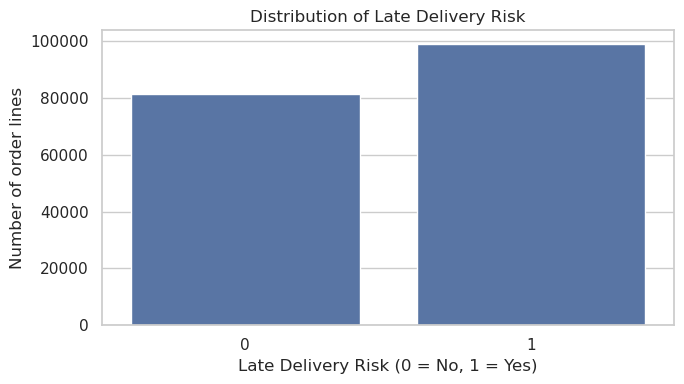

In [52]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x=classification_target)
plt.title("Distribution of Late Delivery Risk")
plt.xlabel("Late Delivery Risk (0 = No, 1 = Yes)")
plt.ylabel("Number of order lines")
plt.tight_layout()
plt.show()

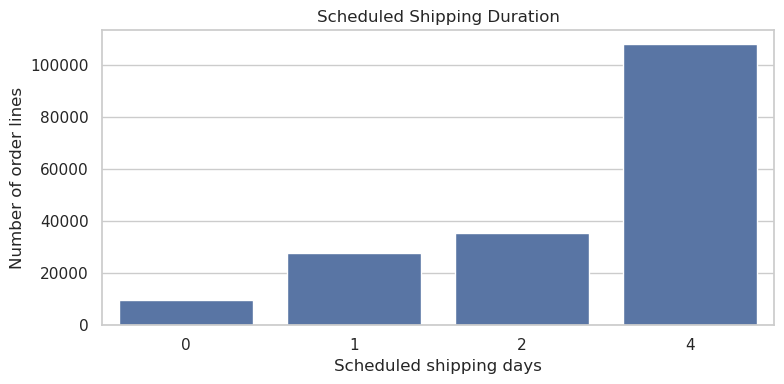

In [53]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x="Days for shipment (scheduled)")
plt.title("Scheduled Shipping Duration")
plt.xlabel("Scheduled shipping days")
plt.ylabel("Number of order lines")
plt.tight_layout()
plt.show()

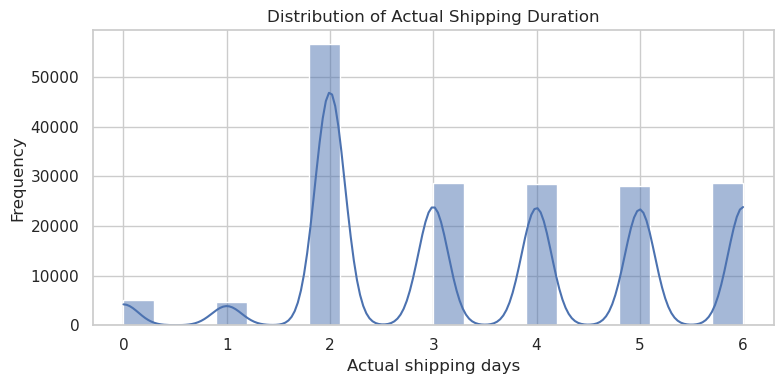

In [54]:
plt.figure(figsize=(8, 4))
sns.histplot(df_clean[regression_target], bins=20, kde=True)
plt.title("Distribution of Actual Shipping Duration")
plt.xlabel("Actual shipping days")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

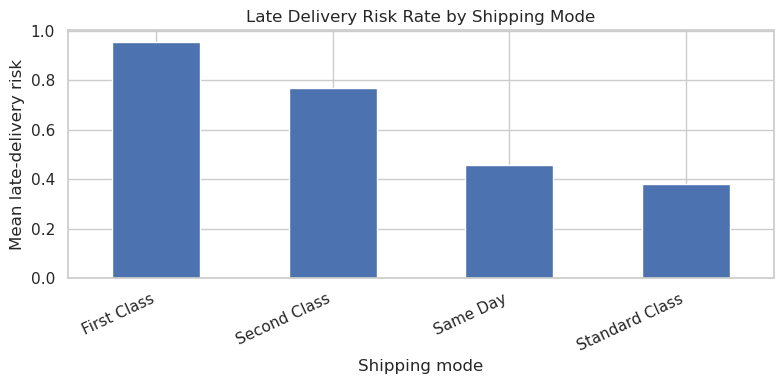

In [55]:
late_rate = df_clean.groupby("Shipping Mode")[classification_target].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 4))
late_rate.plot(kind="bar")
plt.title("Late Delivery Risk Rate by Shipping Mode")
plt.ylabel("Mean late-delivery risk")
plt.xlabel("Shipping mode")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

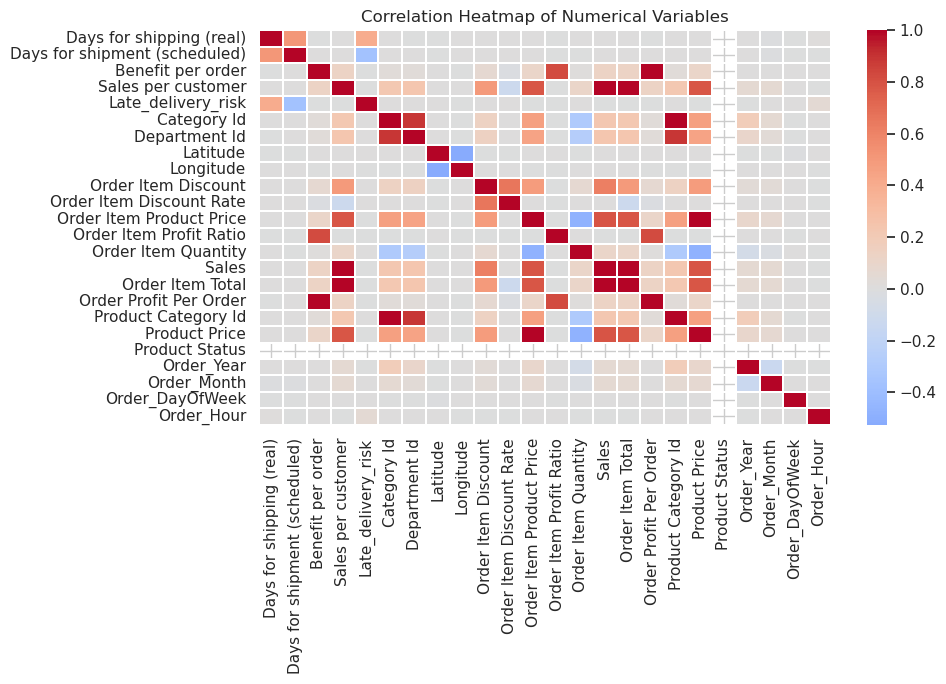

In [56]:
plt.figure(figsize=(10, 7))
numeric_for_corr = df_clean.select_dtypes(include=np.number)
corr = numeric_for_corr.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### EDA interpretation
Use the charts and the printed distributions to describe class balance, shipping-duration patterns, differences across shipping modes, and relationships among numerical variables. Write interpretations based on the actual plots generated on your run; do not assume that a particular shipping mode or feature is the most risky before checking the results.

## 7. Prepare modelling features

In [57]:
# Order Id is retained separately only for group-aware splitting.
# It is never passed to a model as a predictor.
groups = df["Order Id"].reindex(df_clean.index) if "Order Id" in df.columns else pd.Series(
    np.arange(len(df_clean)), index=df_clean.index
)

# Use order-time / order-line information. Exclude both targets and post-outcome fields.
excluded_from_features = [
    regression_target, classification_target,
    "Delivery Status", "Order Status",
    "shipping date (DateOrders)", "Order Id", "Order Item Id",
    "Customer Email", "Customer Password", "Customer Fname", "Customer Lname",
    "Customer Street", "Customer Zipcode", "Order Zipcode",
    "Product Description", "Product Image",
    "Customer Id", "Order Customer Id",
    "Product Card Id", "Order Item Cardprod Id",
    "Benefit per order", "Sales per customer",
    "Order Profit Per Order", "Order Item Profit Ratio"
]

X_all = df_clean.drop(
    columns=[c for c in excluded_from_features if c in df_clean.columns]
).copy()

# Keep a manageable, interpretable set of categorical and numeric predictors.
categorical_candidates = [
    "Type", "Customer Segment", "Market", "Department Name",
    "Order Region", "Order Country", "Shipping Mode", "Category Name"
]
numeric_candidates = [
    "Days for shipment (scheduled)", "Category Id", "Department Id",
    "Order Item Discount", "Order Item Discount Rate",
    "Order Item Product Price", "Order Item Quantity",
    "Sales", "Order Item Total", "Product Price",
    "Latitude", "Longitude",
    "Order_Year", "Order_Month", "Order_DayOfWeek", "Order_Hour"
]

categorical_features = [c for c in categorical_candidates if c in X_all.columns]
numeric_features = [c for c in numeric_candidates if c in X_all.columns]
feature_columns = categorical_features + numeric_features
X = X_all[feature_columns].copy()

y_reg = df_clean[regression_target].astype(float)
y_cls = df_clean[classification_target].astype(int)
groups = groups.loc[X.index]

print("Selected categorical features:", categorical_features)
print("Selected numerical features:", numeric_features)
print("Total model input features before encoding:", len(feature_columns))
display(X.head())

Selected categorical features: ['Type', 'Customer Segment', 'Market', 'Department Name', 'Order Region', 'Order Country', 'Shipping Mode', 'Category Name']
Selected numerical features: ['Days for shipment (scheduled)', 'Category Id', 'Department Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Product Price', 'Latitude', 'Longitude', 'Order_Year', 'Order_Month', 'Order_DayOfWeek', 'Order_Hour']
Total model input features before encoding: 24


,Type,Customer Segment,Market,Department Name,Order Region,Order Country,Shipping Mode,Category Name,Days for shipment (scheduled),Category Id,Department Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Sales,Order Item Total,Product Price,Latitude,Longitude,Order_Year,Order_Month,Order_DayOfWeek,Order_Hour
0,DEBIT,Consumer,Pacific Asia,Fitness,Southeast Asia,Indonesia,Standard Class,Sporting Goods,4,73,2,13.110000,0.04,327.75,1,327.75,314.640015,327.75,18.251453,-66.037056,2018,1,2,22
1,TRANSFER,Consumer,Pacific Asia,Fitness,South Asia,India,Standard Class,Sporting Goods,4,73,2,16.389999,0.05,327.75,1,327.75,311.359985,327.75,18.279451,-66.037064,2018,1,5,12
2,CASH,Consumer,Pacific Asia,Fitness,South Asia,India,Standard Class,Sporting Goods,4,73,2,18.030001,0.06,327.75,1,327.75,309.720001,327.75,37.292233,-121.881279,2018,1,5,12
3,DEBIT,Home Office,Pacific Asia,Fitness,Oceania,Australia,Standard Class,Sporting Goods,4,73,2,22.940001,0.07,327.75,1,327.75,304.809998,327.75,34.125946,-118.291016,2018,1,5,11
4,PAYMENT,Corporate,Pacific Asia,Fitness,Oceania,Australia,Standard Class,Sporting Goods,4,73,2,29.500000,0.09,327.75,1,327.75,298.250000,327.75,18.253769,-66.037048,2018,1,5,11


## 8. Group-aware train/test split

In [58]:
# The full dataset is used for data understanding and EDA.
# To keep model training practical on a student laptop, select a reproducible
# sample of complete orders. All line items for selected orders are retained.
MAX_ORDERS_FOR_MODELLING = 20000
selected_order_ids = groups.drop_duplicates().sample(
    n=min(MAX_ORDERS_FOR_MODELLING, groups.nunique()),
    random_state=RANDOM_STATE
)
model_mask = groups.isin(selected_order_ids)

X = X.loc[model_mask].copy()
y_reg = y_reg.loc[model_mask].copy()
y_cls = y_cls.loc[model_mask].copy()
groups = groups.loc[model_mask].copy()

print("Rows used for modelling:", len(X))
print("Unique orders used for modelling:", groups.nunique())

# Split by Order Id so that line items belonging to one order cannot appear
# in both training and test sets.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y_cls, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_reg_train, y_reg_test = y_reg.iloc[train_idx], y_reg.iloc[test_idx]
y_cls_train, y_cls_test = y_cls.iloc[train_idx], y_cls.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Unique orders in training:", groups_train.nunique())
print("Unique orders in testing:", groups.iloc[test_idx].nunique())
print("Overlap in order IDs:", len(set(groups_train) & set(groups.iloc[test_idx])))

Rows used for modelling: 55106
Unique orders used for modelling: 20000
Training rows: 43973
Testing rows: 11133
Unique orders in training: 16000
Unique orders in testing: 4000
Overlap in order IDs: 0


## 9. Preprocessing pipeline

In [59]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

## 10. Feature selection using Random Forest Feature Importance

,Importance
num__Days for shipment (scheduled),0.232986
cat__Shipping Mode_Standard Class,0.192099
cat__Shipping Mode_First Class,0.153164
cat__Shipping Mode_Second Class,0.064759
num__Order_Hour,0.040069
cat__Shipping Mode_Same Day,0.035360
num__Longitude,0.022187
num__Latitude,0.022061
cat__Type_TRANSFER,0.017024
num__Order Item Total,0.014328


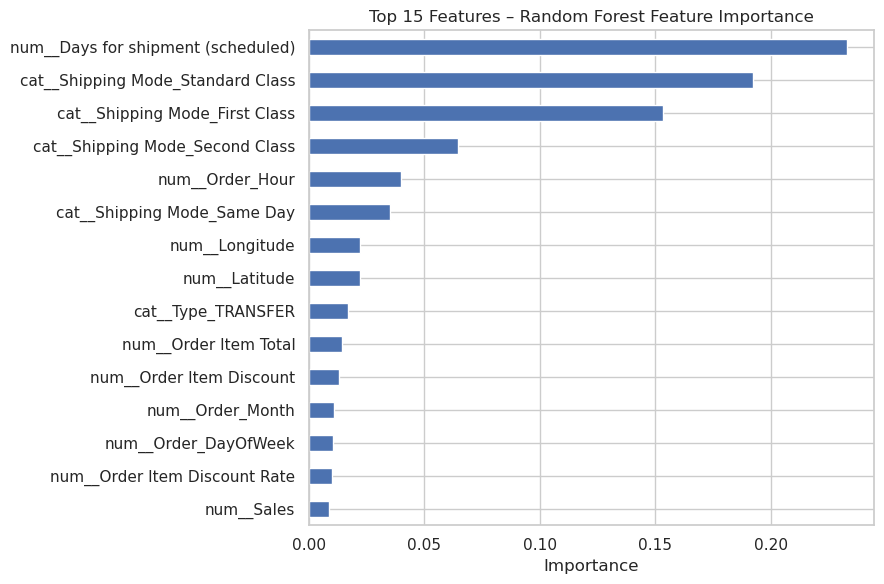

In [60]:
# Fit the preprocessing only on training data.
X_train_processed = preprocessor.fit_transform(X_train)

# Fit feature-selection model on a reproducible subset to keep runtime reasonable.
rng = np.random.RandomState(RANDOM_STATE)
fs_size = min(20000, X_train_processed.shape[0])
fs_idx = rng.choice(X_train_processed.shape[0], size=fs_size, replace=False)

feature_selector_model = RandomForestClassifier(
    n_estimators=100, max_depth=12, random_state=RANDOM_STATE,
    n_jobs=-1, class_weight="balanced"
)
feature_selector_model.fit(X_train_processed[fs_idx], y_cls_train.iloc[fs_idx])

encoded_feature_names = preprocessor.get_feature_names_out()
importance = pd.Series(
    feature_selector_model.feature_importances_,
    index=encoded_feature_names
).sort_values(ascending=False)

display(importance.head(15).to_frame("Importance"))

plt.figure(figsize=(9, 6))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Features – Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### Feature-selection interpretation
Random Forest Feature Importance ranks the encoded input variables according to their contribution to the fitted forest. Discuss the top-ranked variables shown by your run. Importance indicates usefulness to this model; it does not prove causation.

## 11. Regression – three algorithms

In [61]:
regression_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        max_depth=15, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=60, max_depth=15, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

regression_results = []
regression_predictions = {}

for model_name, estimator in regression_models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_reg_train)
    predictions = pipe.predict(X_test)
    regression_predictions[model_name] = predictions

    mae = mean_absolute_error(y_reg_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_reg_test, predictions))
    r2 = r2_score(y_reg_test, predictions)

    regression_results.append({
        "Model": model_name, "MAE": mae, "RMSE": rmse, "R2 Score": r2
    })

regression_results_df = pd.DataFrame(regression_results).sort_values("RMSE")
display(regression_results_df)

,Model,MAE,RMSE,R2 Score
2,Random Forest Regressor,0.966400,1.269285,0.387338
0,Linear Regression,1.001895,1.274360,0.382429
1,Decision Tree Regressor,0.983155,1.305922,0.351460


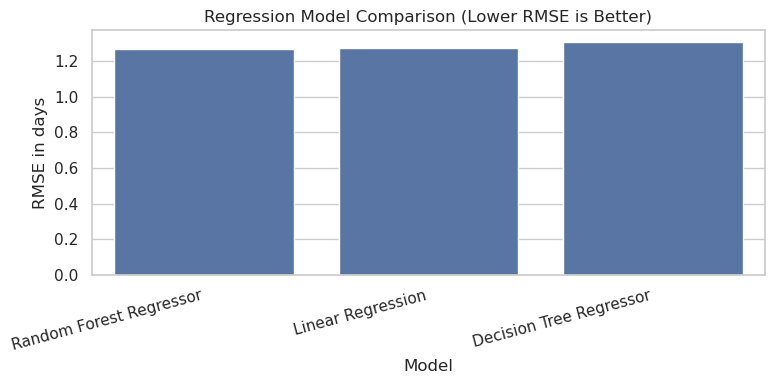

In [62]:
plt.figure(figsize=(8, 4))
sns.barplot(data=regression_results_df, x="Model", y="RMSE")
plt.title("Regression Model Comparison (Lower RMSE is Better)")
plt.ylabel("RMSE in days")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

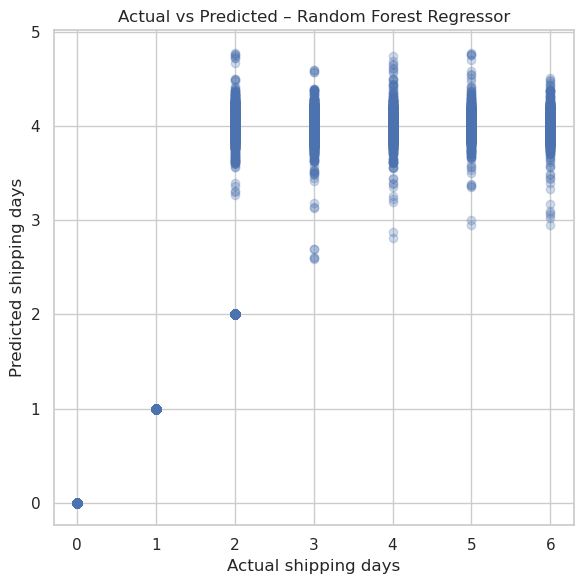

Best regression model by RMSE: Random Forest Regressor


In [63]:
best_regression_name = regression_results_df.iloc[0]["Model"]
best_regression_predictions = regression_predictions[best_regression_name]

plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, best_regression_predictions, alpha=0.25)
plt.xlabel("Actual shipping days")
plt.ylabel("Predicted shipping days")
plt.title(f"Actual vs Predicted – {best_regression_name}")
plt.tight_layout()
plt.show()

print("Best regression model by RMSE:", best_regression_name)

### Regression metrics
- **MAE:** average absolute prediction error, in days.
- **RMSE:** gives larger errors more weight, in days.
- **R²:** proportion of target variation explained by the model.

A lower MAE/RMSE and a higher R² generally indicate better regression performance. Interpret the actual values printed by your notebook.

## 12. Classification – three algorithms

In [64]:
classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Decision Tree Classifier": DecisionTreeClassifier(
        max_depth=15, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=60, max_depth=15, min_samples_leaf=3,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    )
}

classification_results = []
classification_predictions = {}
classification_pipelines = {}

for model_name, estimator in classification_models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_cls_train)
    predictions = pipe.predict(X_test)
    classification_pipelines[model_name] = pipe
    classification_predictions[model_name] = predictions

    classification_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_cls_test, predictions),
        "Precision": precision_score(y_cls_test, predictions, zero_division=0),
        "Recall": recall_score(y_cls_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_cls_test, predictions, zero_division=0)
    })

classification_results_df = pd.DataFrame(classification_results).sort_values(
    "F1 Score", ascending=False
)
display(classification_results_df)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest Classifier,0.724064,0.857483,0.592556,0.700818
1,Decision Tree Classifier,0.699003,0.807736,0.588109,0.680644
0,Logistic Regression,0.696847,0.834366,0.554183,0.666007


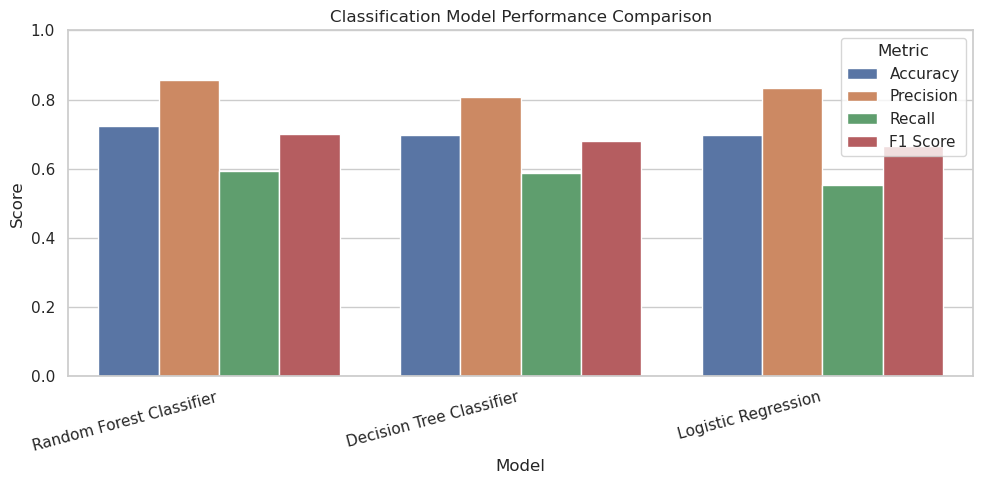

In [65]:
classification_plot = classification_results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric", value_name="Score"
)

plt.figure(figsize=(10, 5))
sns.barplot(data=classification_plot, x="Model", y="Score", hue="Metric")
plt.title("Classification Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

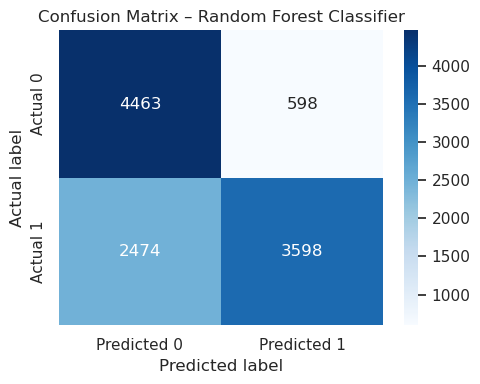

                       precision    recall  f1-score   support

No late-delivery risk       0.64      0.88      0.74      5061
   Late-delivery risk       0.86      0.59      0.70      6072

             accuracy                           0.72     11133
            macro avg       0.75      0.74      0.72     11133
         weighted avg       0.76      0.72      0.72     11133



In [66]:
best_initial_model_name = classification_results_df.iloc[0]["Model"]
best_initial_predictions = classification_predictions[best_initial_model_name]

cm = confusion_matrix(y_cls_test, best_initial_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title(f"Confusion Matrix – {best_initial_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

print(classification_report(
    y_cls_test, best_initial_predictions,
    target_names=["No late-delivery risk", "Late-delivery risk"],
    zero_division=0
))

### Classification metrics
- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** among records predicted as at risk, the fraction that truly are at risk.
- **Recall:** among truly at-risk records, the fraction identified by the model.
- **F1 Score:** harmonic mean of precision and recall.

For a risk-detection project, recall is important because missed late deliveries may be costly. Precision is also important because too many false alarms can waste operational resources.

## 13. Hyperparameter tuning using GridSearchCV

In [67]:
# Tune the Random Forest Classifier using a compact grid.
# GroupKFold keeps each Order Id within only one fold.
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [60],
    "model__max_depth": [10, 20],
    "model__min_samples_leaf": [1, 5]
}

group_cv = GroupKFold(n_splits=3)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=group_cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_cls_train, groups=groups_train)

print("Best parameters:")
print(grid_search.best_params_)
print("Best cross-validation F1 score:", grid_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 60}
Best cross-validation F1 score: 0.6900909540952184


In [68]:
tuned_predictions = grid_search.best_estimator_.predict(X_test)

tuned_metrics = {
    "Accuracy": accuracy_score(y_cls_test, tuned_predictions),
    "Precision": precision_score(y_cls_test, tuned_predictions, zero_division=0),
    "Recall": recall_score(y_cls_test, tuned_predictions, zero_division=0),
    "F1 Score": f1_score(y_cls_test, tuned_predictions, zero_division=0)
}
display(pd.DataFrame([tuned_metrics], index=["Tuned Random Forest"]))

,Accuracy,Precision,Recall,F1 Score
Tuned Random Forest,0.723255,0.854468,0.593709,0.700612


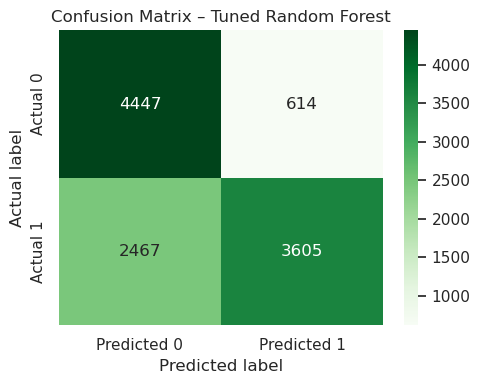

In [69]:
tuned_cm = confusion_matrix(y_cls_test, tuned_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(tuned_cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title("Confusion Matrix – Tuned Random Forest")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

## 14. Final model comparison and interpretation

In [70]:
final_classification_results = classification_results_df.copy()
tuned_row = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    **tuned_metrics
}])
final_classification_results = pd.concat(
    [final_classification_results, tuned_row], ignore_index=True
)
display(final_classification_results.sort_values("F1 Score", ascending=False))

print("Best regression model:", best_regression_name)
print("Best untuned classification model:", best_initial_model_name)
print("Tuned Random Forest best parameters:", grid_search.best_params_)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest Classifier,0.724064,0.857483,0.592556,0.700818
3,Tuned Random Forest,0.723255,0.854468,0.593709,0.700612
1,Decision Tree Classifier,0.699003,0.807736,0.588109,0.680644
2,Logistic Regression,0.696847,0.834366,0.554183,0.666007


Best regression model: Random Forest Regressor
Best untuned classification model: Random Forest Classifier
Tuned Random Forest best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 60}


In [71]:
# Save the actual result tables for use in the project report.
regression_results_df.to_csv("regression_model_results.csv", index=False)
final_classification_results.to_csv("classification_model_results.csv", index=False)
importance.head(30).to_csv("feature_importance_top30.csv", header=["Importance"])

print("Saved regression_model_results.csv")
print("Saved classification_model_results.csv")
print("Saved feature_importance_top30.csv")

Saved regression_model_results.csv
Saved classification_model_results.csv
Saved feature_importance_top30.csv


## 15. Conclusion

Complete this section after running all cells and reviewing the actual results.

Suggested points to discuss:
1. The project used the DataCo Smart Supply Chain dataset to study delivery duration and late-delivery risk.
2. Three regression algorithms were compared using MAE, RMSE, and R².
3. Three classification algorithms were compared using accuracy, precision, recall, and F1 score.
4. Random Forest Feature Importance was used for feature selection.
5. GridSearchCV tuned the Random Forest Classifier using grouped cross-validation.
6. State which models performed best and support the conclusion with the measured test results.
7. Discuss limitations: the dataset contains historical order-line records, and its late-risk label is not a guarantee of future operational risk.

## 16. References

1. Constante, F., Silva, F., and Pereira, A. (2019). *DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS*. Mendeley Data, Version 5. https://doi.org/10.17632/8gx2fvg2k6.5
2. Scikit-learn documentation. https://scikit-learn.org/stable/
3. Pandas documentation. https://pandas.pydata.org/docs/
4. Seaborn documentation. https://seaborn.pydata.org/

---

**Academic integrity note:** Run the notebook yourself, inspect every output, and write your interpretations in your own words. Cite the dataset and any external material you use. Do not report invented model scores.

In [72]:
import joblib
import json
import pandas as pd
from sklearn.pipeline import Pipeline

# Train and save the best regression pipeline
best_regression_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", regression_models[best_regression_name])
])

best_regression_pipeline.fit(X_train, y_reg_train)

# Save the tuned classification model
best_classification_pipeline = grid_search.best_estimator_

joblib.dump(
    best_regression_pipeline,
    "regression_model.joblib"
)

joblib.dump(
    best_classification_pipeline,
    "classification_model.joblib"
)

# Save input information for the Streamlit app
metadata = {
    "feature_columns": feature_columns,
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "category_options": {
        col: X_train[col].dropna().astype(str).value_counts().index.tolist()[:100]
        for col in categorical_features
    },
    "numeric_defaults": {
        col: float(pd.to_numeric(X_train[col], errors="coerce").median())
        for col in numeric_features
    },
    "best_regression_name": best_regression_name
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("All deployment models saved successfully!")

All deployment models saved successfully!
